<a href="https://colab.research.google.com/github/katzcodes/yolo-pothole-detection/blob/main/mindmesh_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mindmesh — one full MP4 + one GPX

This version adds GPX matching to your working mfranzon + BoT-SORT + external road-filter notebook. Run Cells 1–8 in order, inspect the polygon, then run Cells 9–13.

**Inputs:** in Cell 4 set one full MP4 path and its one GPX path, or select both files with upload mode. Keep road_region_filter.py at /content/drive/MyDrive/mindmesh/road_region_filter.py. In Cell 8 retain the road polygon that worked for your camera.

**Synchronization:** you confirmed both recordings start together, so Cell 7 uses offset 0. Video elapsed playback time is added to the first GPX timestamp. Coordinates come only from the GPX; there is no OCR or embedded GPS/date extraction. Use an original, continuous recording at normal speed. If recordings start differently on a future run, change the offset or enter the first frame's timezone-aware time.

**Meaning of locations:** the summary records bus GPS at the last tracked observation. Vehicle occlusion or distance ahead of the bus can make this differ from the pothole's actual ground position. Each local track ID is an observation group, not a guaranteed unique physical pothole. The annotated MP4 is a constant-FPS review copy; CSV times refer to the original MP4.

**Validation:** notebook syntax and synthetic GPX/timing cases were checked locally. The full detector/video pipeline has not been run here on your MP4 and GPX.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Cell 1 — Install packages

Use a fresh Colab runtime; choose a T4 GPU. If Colab requests a restart, restart and continue from Cell 2.


In [ ]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "ultralytics==8.4.147", "huggingface_hub",
    "opencv-python", "pandas==2.2.3", "tqdm", "lap==0.5.13",
])


0

## Cell 2 — Imports and detection settings

The mfranzon model, detector confidence, image size and BoT-SORT settings are retained. Output files are stored in /content/mindmesh_gpx_results.


In [ ]:
import csv
from collections import Counter
from uuid import uuid4
import hashlib
import json
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from google.colab import files
from huggingface_hub import hf_hub_download
from IPython.display import Video, display
from tqdm.auto import tqdm
from ultralytics import YOLO

CONFIDENCE = 0.10
IMAGE_SIZE = 1024
TRACKER = "botsort.yaml"
DEVICE = 0 if torch.cuda.is_available() else "cpu"
SHOW_ROAD_OUTLINE = True

OUTPUT_DIR = Path("/content/mindmesh_gpx_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RAW_OUTPUT = OUTPUT_DIR / "potholes_tracked_raw.mp4"
FINAL_OUTPUT = OUTPUT_DIR / "potholes_tracked.mp4"
SUMMARY_OUTPUT = OUTPUT_DIR / "pothole_track_locations.csv"
CSV_OUTPUT = OUTPUT_DIR / "pothole_tracks.csv"
DETECTIONS_OUTPUT = OUTPUT_DIR / "raw_detections.csv"
SETTINGS_OUTPUT = OUTPUT_DIR / "run_settings.json"
RUN_COMPLETE = False
VIDEO_READY = False

for executable in ("ffmpeg",):
    if shutil.which(executable) is None:
        raise RuntimeError(f"{executable} is required; use a standard Colab runtime.")
print("Ultralytics:", ultralytics.__version__, "| Device:", DEVICE)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.147 | Device: 0


## Cell 3 — Download the pothole model

Uses your working mfranzon checkpoint, not the older notebook’s Samdutse checkpoint.


In [ ]:
weights_path = hf_hub_download(
    repo_id="mfranzon/pothole-yolo26",
    filename="best.pt",
)
with open(weights_path, "rb") as f:
    WEIGHTS_SHA256 = hashlib.file_digest(f, "sha256").hexdigest()
print("Weights ready:", weights_path)


best.pt: reconstructing file:   0%|          |  0.00B / 44.0MB            

best.pt: downloading bytes:           |  0.00B            

Weights ready: /root/.cache/huggingface/hub/models--mfranzon--pothole-yolo26/snapshots/f07efaee2eeb63b24e1ce8c8ac635da985722961/best.pt


## Cell 4 — Select one complete MP4 and one GPX

For long recordings, put both files in Drive and edit VIDEO_PATH and GPX_PATH below. Alternatively set INPUT_MODE="upload" and select exactly two files together: one MP4 and one GPX. There is no folder scan, splitting or one-minute limit.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

INPUT_MODE = "drive"  # "drive" or "upload"
VIDEO_PATH = "/content/drive/MyDrive/mindmesh/pothole-2.mp4"
GPX_PATH = "/content/drive/MyDrive/mindmesh/track.gpx"
RUN_COMPLETE = False
VIDEO_READY = False

if INPUT_MODE == "upload":
    uploaded = files.upload()
    selected = [Path(name).resolve() for name in uploaded]
    del uploaded  # Release the extra in-memory copies of the uploaded files.
    videos = [path for path in selected if path.suffix.lower() == ".mp4"]
    tracks = [path for path in selected if path.suffix.lower() == ".gpx"]
    if len(selected) != 2 or len(videos) != 1 or len(tracks) != 1:
        raise ValueError("Select exactly one MP4 and its one GPX file together, then rerun Cell 4.")
    VIDEO_PATH, GPX_PATH = str(videos[0]), str(tracks[0])
elif INPUT_MODE != "drive":
    raise ValueError('INPUT_MODE must be "drive" or "upload".')

for value, extension in ((VIDEO_PATH, ".mp4"), (GPX_PATH, ".gpx")):
    path = Path(value)
    if path.suffix.lower() != extension or not path.is_file():
        raise FileNotFoundError(f"Choose an existing {extension} file: {path}")
    if path.stat().st_size == 0:
        raise ValueError(f"Input file is empty: {path}")
print("Full video:", VIDEO_PATH)
print("GPX:", GPX_PATH)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Full video: /content/drive/MyDrive/mindmesh/pothole-2.mp4
GPX: /content/drive/MyDrive/mindmesh/track.gpx


## Cell 5 — Load your existing road filter

Loads /content/drive/MyDrive/mindmesh/road_region_filter.py. Keep the working Python file there.


In [ ]:
import importlib.util

HELPER_PATH = Path("/content/drive/MyDrive/mindmesh/road_region_filter.py")
if not HELPER_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {HELPER_PATH}. Upload road_region_filter.py to My Drive/mindmesh, then rerun this cell."
    )

spec = importlib.util.spec_from_file_location("mindmesh_road_region_filter", HELPER_PATH)
if spec is None or spec.loader is None:
    raise ImportError(f"Cannot load {HELPER_PATH}")
helper_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(helper_module)
RoadRegionFilter = helper_module.RoadRegionFilter
print("Loaded:", HELPER_PATH)


Loaded: /content/drive/MyDrive/mindmesh/road_region_filter.py


## Cell 6 — Load the GPX timeline

Keeps GPX recording breaks. Coordinates remain blank for missing coverage, invalid samples, conflicting timestamps or gaps above MAX_GPX_GAP_SEC. Interpolation is a local straight-line approximation. This uses Python’s XML parser, so no new GPX package or helper file is needed.


In [ ]:
"""Time alignment helpers embedded in the single-video Colab notebook."""
from bisect import bisect_left, bisect_right
from datetime import datetime, timedelta, timezone
import math
import xml.etree.ElementTree as ET


def utc_datetime(value):
    """Require an explicit timezone; never guess UTC for a local clock value."""
    if isinstance(value, str):
        value = datetime.fromisoformat(value.strip().replace("Z", "+00:00"))
    if not isinstance(value, datetime) or value.utcoffset() is None:
        raise ValueError("Timestamp needs a timezone, e.g. 2026-09-06T13:14:48+05:30.")
    return value.astimezone(timezone.utc)


def resolve_video_start(gpx_start, first_frame_time=None, offset_seconds=None):
    if (first_frame_time is None) == (offset_seconds is None):
        raise ValueError(
            "Set exactly ONE: VIDEO_FIRST_FRAME_TIME or VIDEO_START_OFFSET_SEC. "
            "Offset 0 is correct only if the first video frame and first GPX point coincide."
        )
    if first_frame_time is not None:
        return utc_datetime(first_frame_time)
    offset = float(offset_seconds)
    if not math.isfinite(offset):
        raise ValueError("Video start offset must be finite.")
    return utc_datetime(gpx_start) + timedelta(seconds=offset)


class PlaybackClock:
    """Normalize decoder time after each successful read(), with no FPS fallback."""
    def __init__(self):
        self.first_ms = None
        self.previous_ms = None

    def elapsed(self, position_ms):
        value = float(position_ms)
        if not math.isfinite(value):
            raise RuntimeError("Decoder returned an invalid frame playback time.")
        if self.previous_ms is not None and value <= self.previous_ms:
            raise RuntimeError(
                "Frame playback times are missing, repeated or decreasing. "
                "Stop here and inspect the original video; GPS timing cannot be trusted."
            )
        if self.first_ms is None:
            self.first_ms = value
        self.previous_ms = value
        return (value - self.first_ms) / 1000.0


class GPXTimeline:
    """Timestamped GPX track points, retaining recording breaks and invalid samples."""
    def __init__(self, path, max_gap_seconds=5.0):
        self.max_gap = float(max_gap_seconds)
        if not math.isfinite(self.max_gap) or self.max_gap <= 0:
            raise ValueError("MAX_GPX_GAP_SEC must be positive and finite.")
        root = ET.parse(path).getroot()
        if root.tag.split("}")[-1] != "gpx":
            raise ValueError("The selected file is not a GPX document.")
        ns = root.tag[:-3]  # '{namespace}' for GPX 1.0/1.1, or '' without one.
        groups = []
        self.first_point_has_time = False
        self.stats = {"raw_points": 0, "missing_time": 0, "duplicates": 0}
        for track in root.findall(ns + "trk"):
            for segment in track.findall(ns + "trkseg"):
                rows = []
                previous_time = None
                for point in segment.findall(ns + "trkpt"):
                    self.stats["raw_points"] += 1
                    time_text = point.findtext(ns + "time")
                    if self.stats["raw_points"] == 1:
                        self.first_point_has_time = bool(time_text and time_text.strip())
                    if not time_text or not time_text.strip():
                        self.stats["missing_time"] += 1
                        if rows:
                            groups.append(rows)
                        rows = []  # Missing-time samples create an interpolation break.
                        continue
                    timestamp = utc_datetime(time_text)
                    if previous_time is not None and timestamp < previous_time:
                        raise ValueError("GPX timestamps decrease within a track segment.")
                    previous_time = timestamp
                    status = "ok"
                    try:
                        lat, lon = float(point.attrib["lat"]), float(point.attrib["lon"])
                        if not (math.isfinite(lat) and math.isfinite(lon)
                                and -90 <= lat <= 90 and -180 <= lon <= 180):
                            raise ValueError("Invalid coordinates")
                    except (KeyError, TypeError, ValueError):
                        lat = lon = None
                        status = "invalid_coordinates"
                    if (point.findtext(ns + "fix") or "").strip().lower() == "none":
                        lat = lon = None
                        status = "no_gps_fix"
                    row = {"time": timestamp, "lat": lat, "lon": lon, "status": status}
                    if rows and timestamp == rows[-1]["time"]:
                        self.stats["duplicates"] += 1
                        if row != rows[-1]:
                            rows[-1].update(lat=None, lon=None, status="conflicting_timestamp")
                    else:
                        rows.append(row)
                if rows:
                    groups.append(rows)
        if not groups:
            raise ValueError("GPX needs timestamped <trkpt> points; routes/waypoints are insufficient.")
        groups.sort(key=lambda rows: rows[0]["time"])
        for previous, current in zip(groups, groups[1:]):
            if current[0]["time"] < previous[-1]["time"]:
                raise ValueError("GPX track segments overlap in time; select the intended recording.")
            if current[0]["time"] == previous[-1]["time"] and current[0] != previous[-1]:
                for row in (current[0], previous[-1]):
                    row.update(lat=None, lon=None, status="conflicting_timestamp")
        self.groups = groups
        self.starts = [rows[0]["time"] for rows in groups]
        self.times = [[row["time"] for row in rows] for rows in groups]
        self.start, self.end = groups[0][0]["time"], groups[-1][-1]["time"]
        valid_times = {row["time"] for rows in groups for row in rows if row["status"] == "ok"}
        if len(valid_times) < 2:
            raise ValueError("GPX needs at least two valid, distinct timestamps.")
        self.stats["valid_unique_times"] = len(valid_times)
        self.stats["invalid_samples"] = sum(row["status"] != "ok" for rows in groups for row in rows)
        self.stats["continuous_groups"] = len(groups)

    def at(self, timestamp):
        timestamp = utc_datetime(timestamp)
        result = {"bus_latitude": None, "bus_longitude": None,
                  "gps_status": "outside_gpx", "gpx_interval_sec": None}
        if timestamp < self.start or timestamp > self.end:
            return result
        group_index = bisect_right(self.starts, timestamp) - 1
        rows, times = self.groups[group_index], self.times[group_index]
        if timestamp > times[-1]:
            result["gps_status"] = "gpx_segment_break"
            return result
        index = bisect_left(times, timestamp)
        if index < len(times) and times[index] == timestamp:
            row = rows[index]
            result.update(bus_latitude=row["lat"], bus_longitude=row["lon"],
                          gps_status="exact" if row["status"] == "ok" else row["status"],
                          gpx_interval_sec=0.0)
            return result
        left, right = rows[index - 1], rows[index]
        gap = (right["time"] - left["time"]).total_seconds()
        result["gpx_interval_sec"] = gap
        if left["status"] != "ok" or right["status"] != "ok":
            result["gps_status"] = "invalid_gpx_bracket"
            return result
        if gap > self.max_gap:
            result["gps_status"] = "gpx_gap_too_large"
            return result
        alpha = (timestamp - left["time"]).total_seconds() / gap
        # Local straight-line approximation for short GPX sampling intervals.
        lon_delta = (right["lon"] - left["lon"] + 180.0) % 360.0 - 180.0
        result.update(
            bus_latitude=left["lat"] + alpha * (right["lat"] - left["lat"]),
            bus_longitude=(left["lon"] + alpha * lon_delta + 180.0) % 360.0 - 180.0,
            gps_status="interpolated",
        )
        return result


MAX_GPX_GAP_SEC = 5.0
RUN_COMPLETE = False
VIDEO_READY = False
gps_timeline = GPXTimeline(GPX_PATH, max_gap_seconds=MAX_GPX_GAP_SEC)
print("GPX first timestamp:", gps_timeline.start.isoformat())
print("GPX last timestamp: ", gps_timeline.end.isoformat())
print("GPX checks:", gps_timeline.stats)


GPX first timestamp: 2026-09-06T07:45:06+00:00
GPX last timestamp:  2026-09-06T07:45:15+00:00
GPX checks: {'raw_points': 10, 'missing_time': 0, 'duplicates': 0, 'valid_unique_times': 10, 'invalid_samples': 0, 'continuous_groups': 1}


## Cell 7 — Align video time with GPX

You confirmed that the video and GPX start together, so leave VIDEO_START_OFFSET_SEC=0.0. For a later recording that starts differently, a positive offset means the video starts after the first GPX point. Alternatively set a timezone-aware VIDEO_FIRST_FRAME_TIME and set the offset to None. No date, clock time or GPS is extracted from the video.


In [ ]:
VIDEO_START_OFFSET_SEC = 0.0  # Confirmed: first frame coincides with first GPX timestamp.
VIDEO_FIRST_FRAME_TIME = None  # Alternative example: "2026-09-06T13:14:48+05:30"
RUN_COMPLETE = False
VIDEO_READY = False
if VIDEO_FIRST_FRAME_TIME is None and not gps_timeline.first_point_has_time:
    raise ValueError(
        "The first GPX point has no timestamp, so simultaneous-start alignment is ambiguous. "
        "Set VIDEO_FIRST_FRAME_TIME to the known first-frame time and VIDEO_START_OFFSET_SEC=None."
    )
VIDEO_START_UTC = resolve_video_start(
    gps_timeline.start,
    first_frame_time=VIDEO_FIRST_FRAME_TIME,
    offset_seconds=VIDEO_START_OFFSET_SEC,
)
print("First video frame UTC:", VIDEO_START_UTC.isoformat())
print("Bus GPS at first frame:", gps_timeline.at(VIDEO_START_UTC))
print("Frame UTC = this start time + elapsed playback time of the original MP4.")


First video frame UTC: 2026-09-06T07:45:06+00:00
Bus GPS at first frame: {'bus_latitude': 28.58708923250882, 'bus_longitude': 77.05998931414798, 'gps_status': 'exact', 'gpx_interval_sec': 0.0}
Frame UTC = this start time + elapsed playback time of the original MP4.


## Cell 8 — Preview your road polygon

Use the same ROAD_POLYGON and MIN_ROAD_OVERLAP that worked in your video notebook. The values below are its original defaults; copy your tuned values here if you changed them. Check the preview and several points in the route, then run Cell 9. After polygon edits, rerun Cells 8–13.


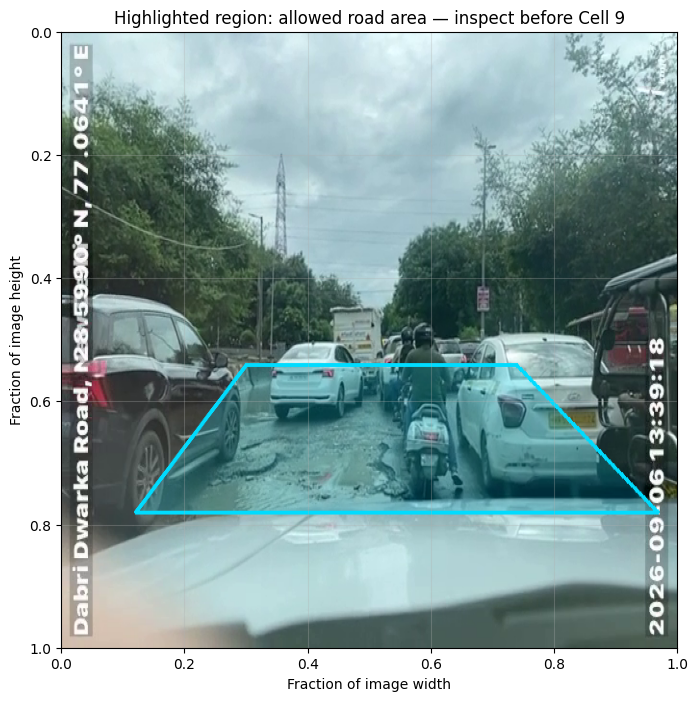

In [ ]:
ROAD_POLYGON = [
    (0.30, 0.54),  # top-left
    (0.74, 0.54),  # top-right
    (0.97, 0.78),  # bottom-right
    (0.12, 0.78),  # bottom-left
]
MIN_ROAD_OVERLAP = 0.60
PREVIEW_SECOND = 5.0
RUN_COMPLETE = False
VIDEO_READY = False
road_filter = RoadRegionFilter(ROAD_POLYGON, MIN_ROAD_OVERLAP)

preview_cap = cv2.VideoCapture(VIDEO_PATH, cv2.CAP_FFMPEG)
try:
    preview_cap.set(cv2.CAP_PROP_POS_MSEC, max(0.0, PREVIEW_SECOND) * 1000.0)
    ok, preview_frame = preview_cap.read()
    if not ok:
        preview_cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
        ok, preview_frame = preview_cap.read()
finally:
    preview_cap.release()
if not ok:
    raise RuntimeError("Could not decode a preview frame.")

preview = road_filter.preview(preview_frame)
plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB), extent=(0, 1, 1, 0))
plt.title("Highlighted region: allowed road area — inspect before Cell 9")
plt.xlabel("Fraction of image width")
plt.ylabel("Fraction of image height")
plt.grid(alpha=0.3)
plt.show()


## Cell 9 — Process the entire video and attach GPX positions

Processes each decoded frame once. GPS uses original playback time through OpenCV’s FFmpeg backend, with no frame/FPS fallback. Detection and tracking receive the original frames. The tracker resets once at the start of this full video. Track summaries use the last actual tracked observation; the end of the file is handled too. Re-running overwrites this notebook’s output files.


In [ ]:
RUN_COMPLETE = False
VIDEO_READY = False
road_filter = RoadRegionFilter(ROAD_POLYGON, MIN_ROAD_OVERLAP)
model = YOLO(weights_path)
if model.task != "detect":
    raise RuntimeError("This notebook requires a bounding-box detection model.")
print("Model classes:", model.names)
model.add_callback("on_predict_postprocess_end", road_filter)

RUN_ID = uuid4().hex
gps_columns = ["bus_latitude", "bus_longitude", "gps_status", "gpx_interval_sec"]
track_columns = ["run_id", "frame", "timestamp_sec", "timestamp_utc", "track_id",
                 "confidence", "x1", "y1", "x2", "y2"] + gps_columns
track_summaries = {}
gps_frame_counts = Counter()
playback_clock = PlaybackClock()
raw_columns = ["frame", "timestamp_sec", "confidence", "class_id", "x1", "y1", "x2", "y2", "road_overlap", "passed_road_filter"]
cap = cv2.VideoCapture(VIDEO_PATH, cv2.CAP_FFMPEG)
writer = None
progress = None
frame_number = 0
raw_count = 0
passed_count = 0
track_ids_seen = set()

try:
    if not cap.isOpened():
        raise RuntimeError("Could not open the input video.")
    fps = float(cap.get(cv2.CAP_PROP_FPS))
    if not np.isfinite(fps) or fps <= 0:
        raise RuntimeError("Video FPS is unavailable; inspect the input metadata.")
    reported_total = float(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    total_frames = int(reported_total) if np.isfinite(reported_total) and reported_total > 0 else None
    progress = tqdm(total=total_frames, desc="Tracking potholes")

    with open(CSV_OUTPUT, "w", newline="") as tf, open(DETECTIONS_OUTPUT, "w", newline="") as rf:
        tracks_csv = csv.writer(tf)
        raw_csv = csv.writer(rf)
        tracks_csv.writerow(track_columns)
        raw_csv.writerow(raw_columns)

        while True:
            ok, frame = cap.read()
            if not ok:
                break
            if writer is None:
                height, width = frame.shape[:2]
                writer = cv2.VideoWriter(
                    str(RAW_OUTPUT), cv2.VideoWriter_fourcc(*"mp4v"), fps,
                    (width, height),
                )
                if not writer.isOpened():
                    raise RuntimeError("Could not create the output video.")
            if frame.shape[:2] != (height, width):
                raise RuntimeError("Frame dimensions changed within the video.")

            # Read the current decoded frame's playback time, not frame_number / FPS.
            timestamp = playback_clock.elapsed(cap.get(cv2.CAP_PROP_POS_MSEC))
            frame_number += 1
            timestamp_utc = VIDEO_START_UTC + timedelta(seconds=timestamp)
            gps = gps_timeline.at(timestamp_utc)
            gps_frame_counts[gps["gps_status"]] += 1
            result = model.track(
                source=frame, persist=True, tracker=TRACKER,
                conf=CONFIDENCE, imgsz=IMAGE_SIZE, device=DEVICE,
                verbose=False,
            )[0]

            # Every detector candidate above CONFIDENCE, before tracker gating.
            for row, overlap, keep in zip(road_filter.last_raw, road_filter.last_overlap, road_filter.last_keep):
                x1, y1, x2, y2, confidence, class_id = row
                raw_csv.writerow([
                    frame_number, timestamp, float(confidence), int(class_id),
                    float(x1), float(y1), float(x2), float(y2),
                    float(overlap), bool(keep),
                ])
            raw_count += len(road_filter.last_raw)
            passed_count += int(road_filter.last_keep.sum())

            annotated = frame.copy()
            if SHOW_ROAD_OUTLINE:
                cv2.polylines(annotated, [road_filter.vertices(frame.shape)], True, (255, 220, 0), 2)
            boxes = result.boxes
            if boxes is not None and boxes.id is not None:
                for box, confidence, track_id in zip(
                    boxes.xyxy.cpu().numpy(), boxes.conf.cpu().numpy(),
                    boxes.id.int().cpu().numpy(),
                ):
                    x1, y1, x2, y2 = map(float, box)
                    track_id, confidence = int(track_id), float(confidence)
                    track_ids_seen.add(track_id)
                    observation = dict(zip(track_columns, [
                        RUN_ID, frame_number, timestamp, timestamp_utc.isoformat(), track_id,
                        confidence, x1, y1, x2, y2,
                    ] + [gps[name] for name in gps_columns]))
                    tracks_csv.writerow([observation[name] for name in track_columns])
                    if track_id not in track_summaries:
                        track_summaries[track_id] = {
                            "first_seen_sec": timestamp,
                            "first_seen_utc": timestamp_utc.isoformat(),
                            "observation_count": 0, "max_confidence": confidence,
                        }
                    summary = track_summaries[track_id]
                    summary["observation_count"] += 1
                    summary["max_confidence"] = max(summary["max_confidence"], confidence)
                    # Replace the whole last observation, including unavailable GPS.
                    # Never substitute an earlier coordinate for a later missing one.
                    summary.update(observation)
                    a, b, c, d = map(int, box)
                    cv2.rectangle(annotated, (a, b), (c, d), (0, 255, 0), 2)
                    cv2.putText(annotated, f"Pothole ID {track_id} | {confidence:.2f}",
                                (a, max(20, b - 8)), cv2.FONT_HERSHEY_SIMPLEX,
                                0.6, (0, 255, 0), 2, cv2.LINE_AA)
            writer.write(annotated)
            progress.update(1)
finally:
    cap.release()
    if writer is not None:
        writer.release()
    if progress is not None:
        progress.close()

if frame_number == 0:
    raise RuntimeError("The input video did not produce any frames.")
if total_frames is not None and frame_number != total_frames:
    raise RuntimeError(
        f"Decoded {frame_number} frames; metadata reports {total_frames}. Check the input before exporting."
    )

summary_columns = [
    "run_id", "track_id", "first_seen_sec", "first_seen_utc", "last_seen_sec", "last_seen_utc",
    "last_seen_frame", "observation_count", "max_confidence", "last_confidence",
    "bus_latitude", "bus_longitude", "gps_status", "gpx_interval_sec", "location_basis",
]
with open(SUMMARY_OUTPUT, "w", newline="") as sf:
    summary_csv = csv.DictWriter(sf, fieldnames=summary_columns)
    summary_csv.writeheader()
    for track_id, row in sorted(track_summaries.items()):
        summary_csv.writerow({
            "run_id": RUN_ID, "track_id": track_id,
            "first_seen_sec": row["first_seen_sec"], "first_seen_utc": row["first_seen_utc"],
            "last_seen_sec": row["timestamp_sec"], "last_seen_utc": row["timestamp_utc"],
            "last_seen_frame": row["frame"], "observation_count": row["observation_count"],
            "max_confidence": row["max_confidence"], "last_confidence": row["confidence"],
            **{name: row[name] for name in gps_columns},
            "location_basis": "bus_gpx_at_last_tracked_observation",
        })

if not any(gps_frame_counts[name] for name in ("exact", "interpolated")):
    raise RuntimeError("No decoded frame has usable GPX coverage; inspect alignment and GPX checks.")

settings = {
    "run_id": RUN_ID,
    "input_gpx": Path(GPX_PATH).name,
    "gpx_sha256": hashlib.sha256(Path(GPX_PATH).read_bytes()).hexdigest(),
    "gpx_start_utc": gps_timeline.start.isoformat(),
    "gpx_end_utc": gps_timeline.end.isoformat(),
    "gpx_checks": gps_timeline.stats,
    "max_gpx_gap_sec": MAX_GPX_GAP_SEC,
    "video_start_utc": VIDEO_START_UTC.isoformat(),
    "video_start_offset_sec": VIDEO_START_OFFSET_SEC,
    "video_first_frame_time": VIDEO_FIRST_FRAME_TIME,
    "gps_frame_counts": dict(gps_frame_counts),
    "last_frame_elapsed_sec": timestamp,
    "input_video": Path(VIDEO_PATH).name,
    "ultralytics_version": ultralytics.__version__,
    "weights_sha256": WEIGHTS_SHA256,
    "confidence": CONFIDENCE, "image_size": IMAGE_SIZE,
    "road_polygon": ROAD_POLYGON, "min_road_overlap": MIN_ROAD_OVERLAP,
    "tracker": TRACKER,
    "tracker_config": (Path(ultralytics.__file__).parent / "cfg" / "trackers" / TRACKER).read_text(),
    "frames_processed": frame_number,
    "road_filter_path": str(HELPER_PATH),
    "timestamp_basis": "OpenCV FFmpeg decoded frame POS_MSEC, normalized to first decoded frame",
    "output_video_fps": fps,
    "output_video_note": "Silent constant-FPS review video. Its playback clock may differ from the input; GPS CSVs use original input frame times.",
}
SETTINGS_OUTPUT.write_text(json.dumps(settings, indent=2))
RUN_COMPLETE = True
print("Tracking finished.")
print("Detector boxes:", raw_count, "| Passed road filter:", passed_count)
print("Distinct local track IDs:", len(track_ids_seen), "(not a verified pothole count)")

print("GPX coverage by frame:", dict(gps_frame_counts))
print("Original video last-frame time:", round(timestamp, 3), "seconds")
print("Track locations:", SUMMARY_OUTPUT)
print("Locations represent the bus at the last tracked observation, not measured pothole ground positions.")


Model classes: {0: 'Pothole'}


Tracking potholes:   0%|          | 0/145 [00:00<?, ?it/s]

Tracking finished.
Detector boxes: 606 | Passed road filter: 360
Distinct local track IDs: 9 (not a verified pothole count)
GPX coverage by frame: {'exact': 7, 'interpolated': 138}
Original video last-frame time: 6.0 seconds
Track locations: /content/mindmesh_gpx_results/pothole_track_locations.csv
Locations represent the bus at the last tracked observation, not measured pothole ground positions.


## Cell 10 — Inspect the GPX results

pothole_tracks.csv has one row per tracked observation with its bus GPS. pothole_track_locations.csv has one row per local tracking ID at its last observation. These IDs are not verified unique physical potholes. Missing GPS stays blank with a reason. An offline summary needs no two-frame disappearance wait; it uses the actual last observation in the full video.


In [ ]:
if not RUN_COMPLETE:
    raise RuntimeError("Complete Cell 9 successfully first.")
display(pd.read_csv(SUMMARY_OUTPUT, nrows=20))
display(pd.read_csv(CSV_OUTPUT, nrows=10))
print("Per-track last observations:", SUMMARY_OUTPUT)
print("All tracked observations:", CSV_OUTPUT)
print("Raw detector candidates:", DETECTIONS_OUTPUT)


,run_id,track_id,first_seen_sec,first_seen_utc,last_seen_sec,last_seen_utc,last_seen_frame,observation_count,max_confidence,last_confidence,bus_latitude,bus_longitude,gps_status,gpx_interval_sec,location_basis
0,9fc2f807595846dda22be643d3f7546c,1,0.583333,2026-09-06T07:45:06.583333+00:00,1.791667,2026-09-06T07:45:07.791667+00:00,44,30,0.695025,0.631090,28.587140,77.060031,interpolated,1.0,bus_gpx_at_last_tracked_observation
1,9fc2f807595846dda22be643d3f7546c,4,2.416667,2026-09-06T07:45:08.416667+00:00,2.625000,2026-09-06T07:45:08.625000+00:00,64,6,0.454444,0.208761,28.587170,77.060056,interpolated,1.0,bus_gpx_at_last_tracked_observation
2,9fc2f807595846dda22be643d3f7546c,6,2.458333,2026-09-06T07:45:08.458333+00:00,2.583333,2026-09-06T07:45:08.583333+00:00,63,4,0.404002,0.152018,28.587169,77.060055,interpolated,1.0,bus_gpx_at_last_tracked_observation
3,9fc2f807595846dda22be643d3f7546c,16,3.291667,2026-09-06T07:45:09.291667+00:00,4.416667,2026-09-06T07:45:10.416667+00:00,107,28,0.666600,0.174619,28.587225,77.060101,interpolated,1.0,bus_gpx_at_last_tracked_observation
4,9fc2f807595846dda22be643d3f7546c,21,3.791667,2026-09-06T07:45:09.791667+00:00,5.000000,2026-09-06T07:45:11+00:00,121,29,0.581734,0.172109,28.587240,77.060114,exact,0.0,bus_gpx_at_last_tracked_observation
5,9fc2f807595846dda22be643d3f7546c,23,4.583333,2026-09-06T07:45:10.583333+00:00,5.208333,2026-09-06T07:45:11.208333+00:00,126,15,0.621147,0.148905,28.587245,77.060118,interpolated,1.0,bus_gpx_at_last_tracked_observation
6,9fc2f807595846dda22be643d3f7546c,24,4.583333,2026-09-06T07:45:10.583333+00:00,4.833333,2026-09-06T07:45:10.833333+00:00,117,6,0.550480,0.144074,28.587236,77.060110,interpolated,1.0,bus_gpx_at_last_tracked_observation
7,9fc2f807595846dda22be643d3f7546c,25,4.875000,2026-09-06T07:45:10.875000+00:00,6.000000,2026-09-06T07:45:12+00:00,145,28,0.466079,0.148287,28.587262,77.060132,exact,0.0,bus_gpx_at_last_tracked_observation
8,9fc2f807595846dda22be643d3f7546c,28,5.375000,2026-09-06T07:45:11.375000+00:00,6.000000,2026-09-06T07:45:12+00:00,145,16,0.576825,0.553968,28.587262,77.060132,exact,0.0,bus_gpx_at_last_tracked_observation


,run_id,frame,timestamp_sec,timestamp_utc,track_id,confidence,x1,y1,x2,y2,bus_latitude,bus_longitude,gps_status,gpx_interval_sec
0,9fc2f807595846dda22be643d3f7546c,15,0.583333,2026-09-06T07:45:06.583333+00:00,1,0.387861,329.815857,328.931152,350.832397,346.644562,28.587107,77.060004,interpolated,1.0
1,9fc2f807595846dda22be643d3f7546c,16,0.625000,2026-09-06T07:45:06.625000+00:00,1,0.480833,328.024384,330.328156,348.959015,346.697083,28.587109,77.060006,interpolated,1.0
2,9fc2f807595846dda22be643d3f7546c,17,0.666667,2026-09-06T07:45:06.666667+00:00,1,0.519984,326.101501,331.164337,348.518494,348.096771,28.587110,77.060007,interpolated,1.0
3,9fc2f807595846dda22be643d3f7546c,18,0.708333,2026-09-06T07:45:06.708333+00:00,1,0.511718,324.136749,330.642303,347.636963,348.384613,28.587111,77.060008,interpolated,1.0
4,9fc2f807595846dda22be643d3f7546c,19,0.750000,2026-09-06T07:45:06.750000+00:00,1,0.516453,322.918823,331.307343,347.194153,350.483978,28.587113,77.060009,interpolated,1.0
5,9fc2f807595846dda22be643d3f7546c,20,0.791667,2026-09-06T07:45:06.791667+00:00,1,0.478217,322.341034,333.037476,346.796631,351.785400,28.587114,77.060010,interpolated,1.0
6,9fc2f807595846dda22be643d3f7546c,21,0.833333,2026-09-06T07:45:06.833333+00:00,1,0.520633,321.792725,333.609711,347.028687,352.159271,28.587115,77.060011,interpolated,1.0
7,9fc2f807595846dda22be643d3f7546c,22,0.875000,2026-09-06T07:45:06.875000+00:00,1,0.485085,320.539520,333.990723,346.796997,352.624573,28.587117,77.060012,interpolated,1.0
8,9fc2f807595846dda22be643d3f7546c,23,0.916667,2026-09-06T07:45:06.916667+00:00,1,0.515849,317.747284,334.491272,346.088928,354.575317,28.587118,77.060013,interpolated,1.0
9,9fc2f807595846dda22be643d3f7546c,24,0.958333,2026-09-06T07:45:06.958333+00:00,1,0.540704,316.928833,335.467468,345.314697,355.961121,28.587119,77.060014,interpolated,1.0


Per-track last observations: /content/mindmesh_gpx_results/pothole_track_locations.csv
All tracked observations: /content/mindmesh_gpx_results/pothole_tracks.csv
Raw detector candidates: /content/mindmesh_gpx_results/raw_detections.csv


## Cell 11 — Convert the annotated video for playback

The annotated MP4 is a silent constant-FPS review copy, as in your working notebook. On variable-rate inputs, its playback time may differ from the source. Use CSV timestamp_sec against the original MP4 for GPS verification.


In [ ]:
if not RUN_COMPLETE:
    raise RuntimeError("Complete Cell 9 successfully first.")
VIDEO_READY = False
subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error",
    "-i", str(RAW_OUTPUT),
    "-vf", "pad=ceil(iw/2)*2:ceil(ih/2)*2",
    "-c:v", "libx264", "-preset", "fast", "-crf", "20",
    "-pix_fmt", "yuv420p", "-movflags", "+faststart", str(FINAL_OUTPUT),
], check=True)
if not FINAL_OUTPUT.exists() or FINAL_OUTPUT.stat().st_size == 0:
    raise RuntimeError("Video conversion did not produce an output file.")
VIDEO_READY = True
print("Ready:", FINAL_OUTPUT)


Ready: /content/mindmesh_gpx_results/potholes_tracked.mp4


## Cell 12 — Display the result

Large outputs are downloaded in the following cell rather than embedded into the notebook.


In [ ]:
if not VIDEO_READY:
    raise RuntimeError("Run Cell 11 successfully first.")
if FINAL_OUTPUT.stat().st_size <= 30 * 1024 * 1024:
    display(Video(str(FINAL_OUTPUT), embed=True, width=1000))
else:
    print("Video is ready. Use Cell 13 to download the larger output.")


## Cell 13 — Download results

Downloads the annotated video, per-observation GPS CSV, per-track last-location CSV, raw detections and run settings. Save the ZIP before the Colab runtime ends.


In [ ]:
import zipfile

if not RUN_COMPLETE or not VIDEO_READY:
    raise RuntimeError("Complete Cells 9 and 11 successfully first.")
ZIP_OUTPUT = Path("/content/mindmesh_gpx_results.zip")
with zipfile.ZipFile(ZIP_OUTPUT, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in (FINAL_OUTPUT, CSV_OUTPUT, SUMMARY_OUTPUT, DETECTIONS_OUTPUT, SETTINGS_OUTPUT):
        archive.write(path, arcname=path.name)
files.download(str(ZIP_OUTPUT))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Implementation references

- [Older GPX notebook inspected](https://colab.research.google.com/drive/1lAYY-FCe0c2Dwx63n3619VkkPY2MSQvn?usp=sharing): its one-minute setting checks consecutive clip start intervals; the notebook does not itself split videos.
- [GPX schema](https://www.topografix.com/GPX/1/1/): timestamped track points and separate track segments.
- [OpenCV video properties](https://docs.opencv.org/4.x/d4/d15/group__videoio__flags__base.html): video playback time and backend-dependent properties.
- [OpenCV FFmpeg implementation](https://github.com/opencv/opencv/blob/4.x/modules/videoio/src/cap_ffmpeg_impl.hpp): POS_MSEC after decoding derives from frame timing. The notebook rejects repeated or decreasing values.


In [ ]:
metrics = model.val()


Ultralytics 8.4.147 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,350,223 parameters, 0 gradients, 68.1 GFLOPs


FileNotFoundError: 'pothole.yaml' does not exist